# Model Training 2 - Random Forest Regressor
Using the [yggdrasil-decision-forest (ydf)](https://ydf.readthedocs.io/en/stable/py_api/RandomForestLearner/) library

## 1. Feature Selection

In [2]:
# import libraries
import pandas as pd
from sklearn.model_selection import train_test_split
import ydf
import matplotlib.pyplot as plt
import plotly
from IPython.display import HTML
import seaborn as sns
import numpy as np
%matplotlib inline

In [3]:
# read train and test data
train_df = pd.read_csv('../Data/Train.csv')
test_df = pd.read_csv('../Data/Test.csv')

In [4]:
# function to plot model evaluation
sns.set_theme(style="whitegrid")

def plot_model_evaluation(y_true, y_pred, title="Model Evaluation"):
    """
    Plot residual, prediction, and ground truth diagnostics for regression models.
    
    Parameters:
        y_true (array-like): Ground truth values
        y_pred (array-like): Model predictions
        title (str): Title of the overall plot
    """
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()
    residuals = y_pred - y_true

    # Create figure layout
    fig, axs = plt.subplots(3, 2, figsize=(14, 14))
    fig.suptitle(title, fontsize=16)

    # 1. Residual Histogram
    sns.histplot(residuals, bins=60, ax=axs[0, 0], color="C0")
    axs[0, 0].set_title("Residual Histogram")
    axs[0, 0].set_xlabel("Residual")
    axs[0, 0].set_ylabel("Density")

    # 2. Ground Truth Histogram
    sns.histplot(y_true, bins=60, ax=axs[0, 1], color="C0")
    axs[0, 1].set_title("Ground Truth Histogram")
    axs[0, 1].set_xlabel("Ground truth")
    axs[0, 1].set_ylabel("Density")

    # 3. Prediction Histogram
    sns.histplot(y_pred, bins=60, ax=axs[1, 0], color="C0")
    axs[1, 0].set_title("Prediction Histogram")
    axs[1, 0].set_xlabel("Prediction")
    axs[1, 0].set_ylabel("Density")

    # 4. Ground Truth vs Predictions (binned)
    df_gt_pred = pd.DataFrame({"ground_truth": y_true, "prediction": y_pred})
    df_gt_pred["gt_bin"] = pd.cut(df_gt_pred["ground_truth"], bins=30)
    binned_gt = df_gt_pred.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["prediction"], label="Prediction", color="darkorange")
    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["ground_truth"], linestyle="--", color="C0", label="Ideal")
    axs[1, 1].set_title("Ground Truth vs Predictions (Binned)")
    axs[1, 1].set_xlabel("Ground Truth")
    axs[1, 1].set_ylabel("Prediction")
    axs[1, 1].legend()

    # 5. Predictions vs Residual (binned)
    df_pred_res = pd.DataFrame({"prediction": y_pred, "residual": residuals})
    df_pred_res["pred_bin"] = pd.cut(df_pred_res["prediction"], bins=30)
    binned_pred = df_pred_res.groupby("pred_bin", observed=False).mean(numeric_only=True)

    axs[2, 0].plot(binned_pred["prediction"], binned_pred["residual"], color="darkorange")
    axs[2, 0].axhline(0, linestyle="--", color="C0")
    axs[2, 0].set_title("Predictions vs Residual (Binned)")
    axs[2, 0].set_xlabel("Prediction")
    axs[2, 0].set_ylabel("Residual")

    # 6. Ground Truth vs Residual (binned)
    df_gt_res = pd.DataFrame({"ground_truth": y_true, "residual": residuals})
    df_gt_res["gt_bin"] = pd.cut(df_gt_res["ground_truth"], bins=30)
    binned_gt_res = df_gt_res.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[2, 1].plot(binned_gt_res["ground_truth"], binned_gt_res["residual"], color="darkorange")
    axs[2, 1].axhline(0, linestyle="--", color="C0")
    axs[2, 1].set_title("Ground Truth vs Residual (Binned)")
    axs[2, 1].set_xlabel("Ground Truth")
    axs[2, 1].set_ylabel("Residual")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


### Model 1.1 - using all default features
Not use engineered feature 'DAYS_SINCE_LAUNCH' yet

In [24]:
# train model
features1_1 = ['OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH', 
             'EPOCH', 'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD']
model1_1 = ydf.RandomForestLearner(task=ydf.Task.REGRESSION, features=features1_1, label='LIFETIME').train(train_df, verbose=2)

Train model on 19550 examples
Model trained in 0:00:27.635306


In [25]:
description1_1 = model1_1.describe()
description1_1

In [26]:
# evaluate the model
evaluation1_1 = model1_1.evaluate(test_df)
print(evaluation1_1)

RMSE: 1570.27
num examples: 4888
num examples (weighted): 4888



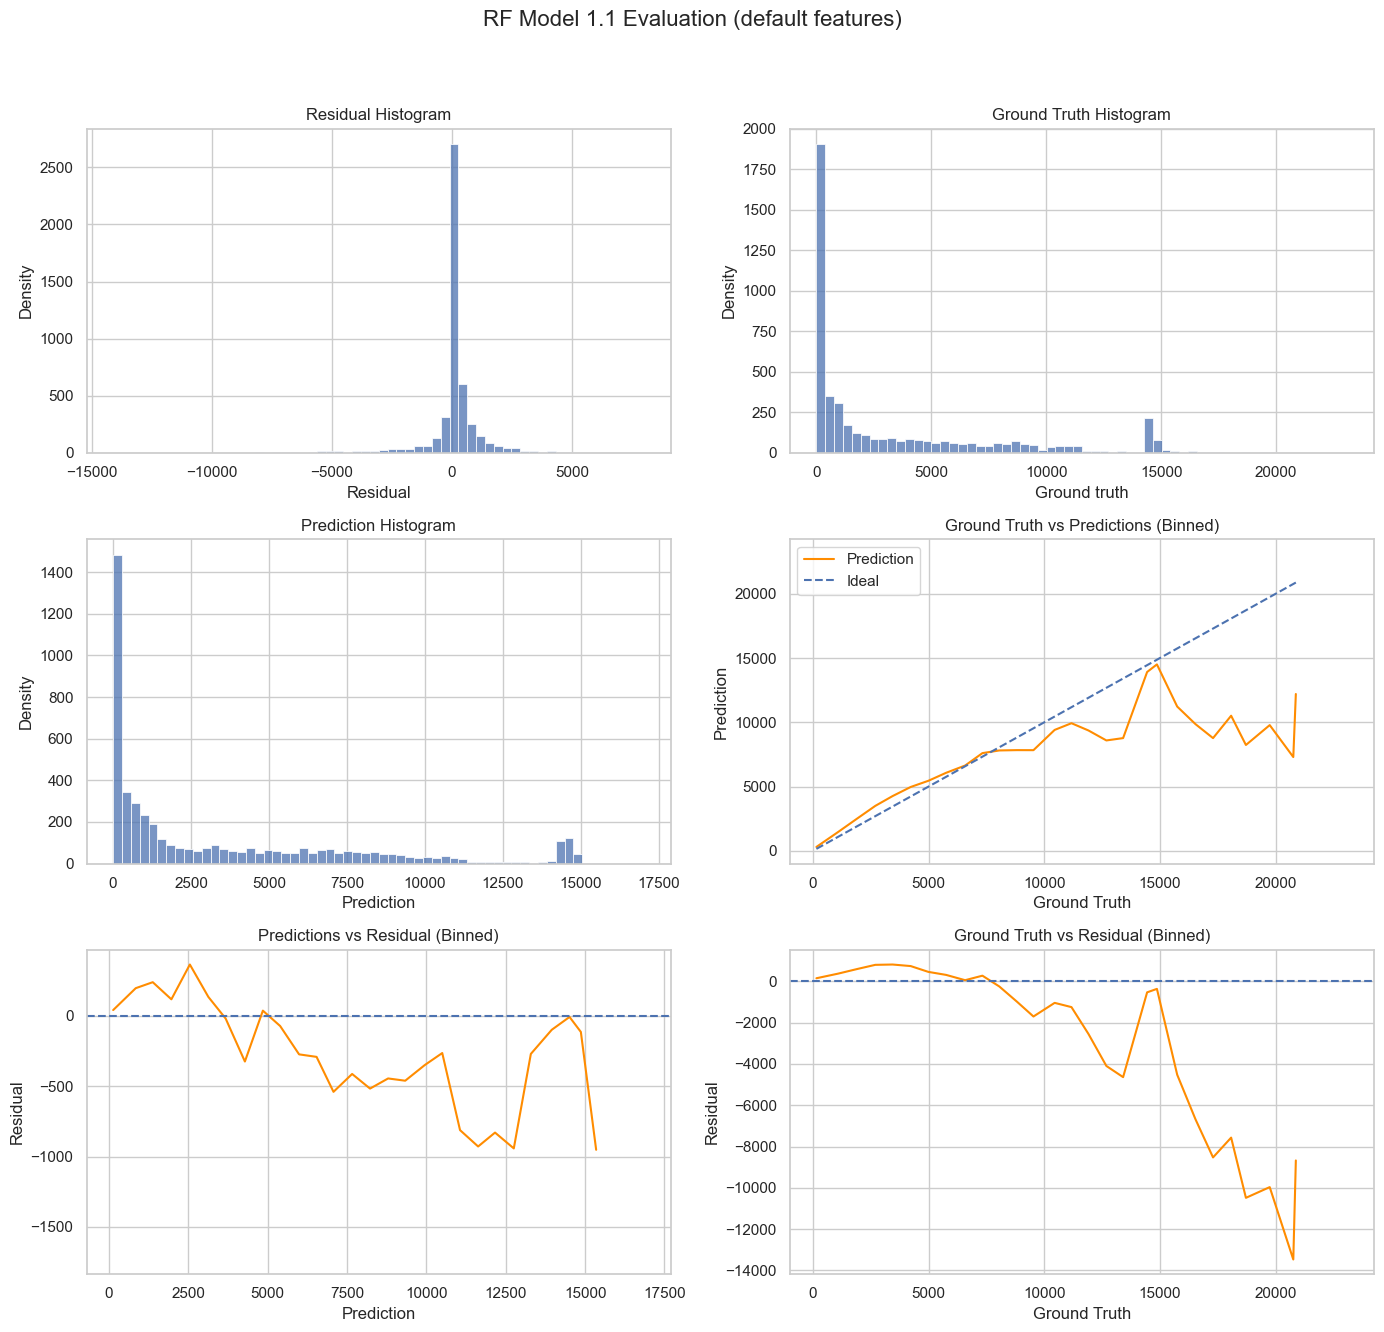

In [27]:
# plot model evaluation
y_true = test_df['LIFETIME']
y_pred1_1 = model1_1.predict(test_df)
plot_model_evaluation(y_true, y_pred1_1, title="RF Model 1.1 Evaluation (default features)")

#### Interpretation Evaluation
1. Residual Histogram: Many Predictions near 0 -> correct, right-side skew -> overestimating<br>
3. Prediction Histogram: Model underestimates the tail (compared to Ground Truth Histogram)<br>
4. Ground Truth vs. Predictions: Good accuracy for small lifetimes (tendency towards overestimating); Starting around 10k–12k, the line begins to flatten → the model underpredicts higher values (except good accuracy for objects with little below 15000 days lifetime, that appear more often in the data)
5. Prediction vs. Residual: near 0 residuals for low predictions -> good fit, as predictions increase the residuals increase sharply -> possibly missclassifies low-GT samples as high one

In [28]:
# analyze the model
analysis1_1 = model1_1.analyze(test_df)
analysis1_1

#### Interpretation Analysis
Partial Dependence Plots:
- Rocket bodies decay faster on average than debris
- Country and Site have a significant (yet not physical) impact on lifetime as well, distribution very imbalanced (CIS/US and TTMTR/PKMTR most represented)
- Periapsis: the lower the periapsis the shorter the lifetime -> low orbits decay faster
- Mean Motion: higher mean motion -> lower orbit -> stronger drag -> shorter lifetime
- Revolution at Epoch: higher revs -> longer lifetime
- BSTAR: counterintuitive, higher drag should lead to objects decaying faster
- Semimajor Axis: the shorter the shorter the lifetime (measure for altitude)
- Mean Motion Dot: for most objects between 0 and 0.01
- Period: the longer the longer the lifetime

In [29]:
# save the model
model1_1.save('../Models/RF1_1.ydf')

### Model 1.2 - Including engineered feature 'DAYS_SINCE_LAUNCH'


In [30]:
# train model
features1_2 = ['OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH', 
             'EPOCH', 'DAYS_SINCE_LAUNCH', 'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD']
model1_2 = ydf.RandomForestLearner(task=ydf.Task.REGRESSION, features=features1_2, label='LIFETIME').train(train_df, verbose=2)

Train model on 19550 examples
Model trained in 0:00:40.201976


In [31]:
description1_2 = model1_2.describe()
description1_2

In [32]:
# evaluate the model
evaluation1_2 = model1_2.evaluate(test_df)
print(evaluation1_2)

RMSE: 802.47
num examples: 4888
num examples (weighted): 4888



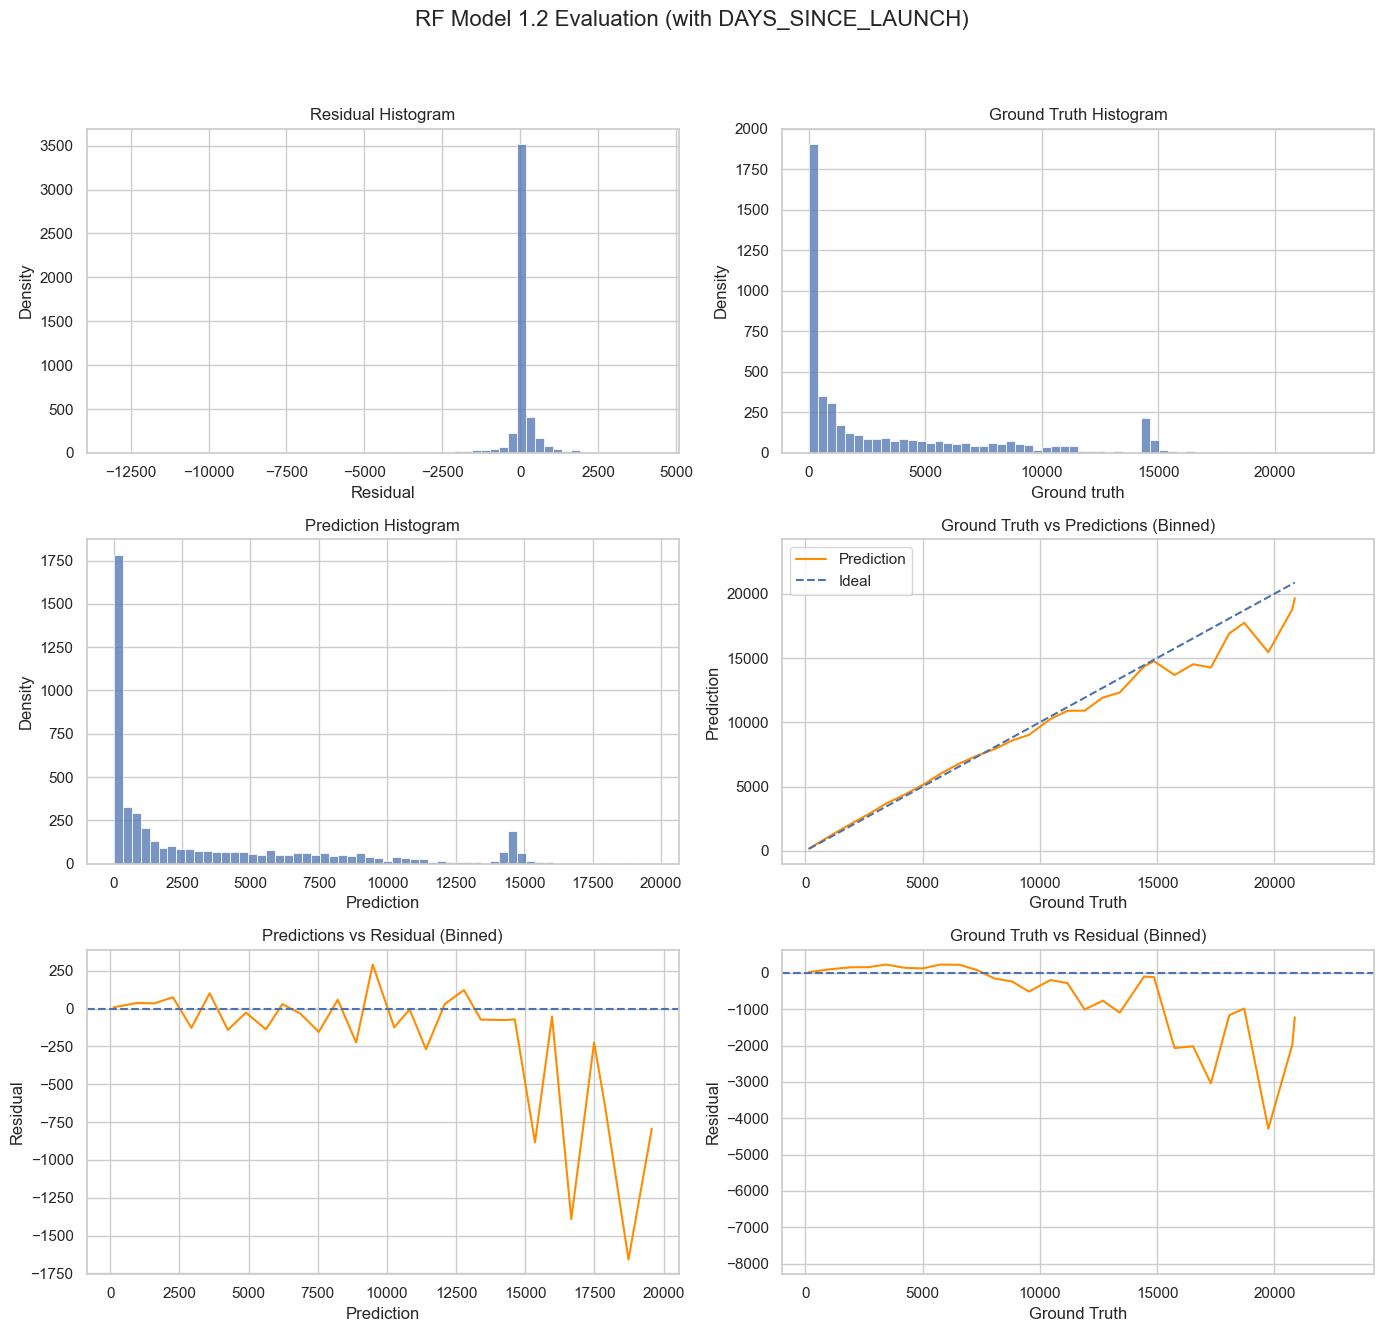

In [33]:
# plot model evaluation
y_true = test_df['LIFETIME']
y_pred1_2 = model1_2.predict(test_df)
plot_model_evaluation(y_true, y_pred1_2, title="RF Model 1.2 Evaluation (with DAYS_SINCE_LAUNCH)")

In [34]:
# analyze the model
analysis1_2 = model1_2.analyze(test_df)
analysis1_2

#### Interpretation Analysis
DAYS_SINCE_LAUNCH: Variable importance is not correct, difference from Model 1 (without) and Model 2 (with) is 1451.29 - 756.904 = 694.386 <br>
The feature DAYS_SINCE_LAUNCH significantly improves the performance of the RF because, for many objects with very short lifetimes, the randomly chosen epoch is close to their decay date and thus the lifetime can be inferred from this feature. 

In [35]:
# save the model
model1_2.save('../Models/RF1_2.ydf')

### Model 1.3 - Remove not needed features 
(MEAN_ANOMALY, MEAN_MOTION_DDOT, ARG_OF_PERICENTER & EPOCH)

In [36]:
# train model
features1_3 = ['OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH', 
             'DAYS_SINCE_LAUNCH', 'PERIAPSIS', 'APOAPSIS', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'SEMIMAJOR_AXIS', 'PERIOD']
model1_3 = ydf.RandomForestLearner(task=ydf.Task.REGRESSION, features=features1_3, label='LIFETIME').train(train_df, verbose=2)

Train model on 19550 examples
Model trained in 0:00:22.035445


In [37]:
# describe model
description1_3 = model1_3.describe()
description1_3

In [38]:
# show rmse
evaluation1_3 = model1_3.evaluate(test_df)
print(evaluation1_3)

RMSE: 798.241
num examples: 4888
num examples (weighted): 4888



#### RSME only got marginally better (0.01)

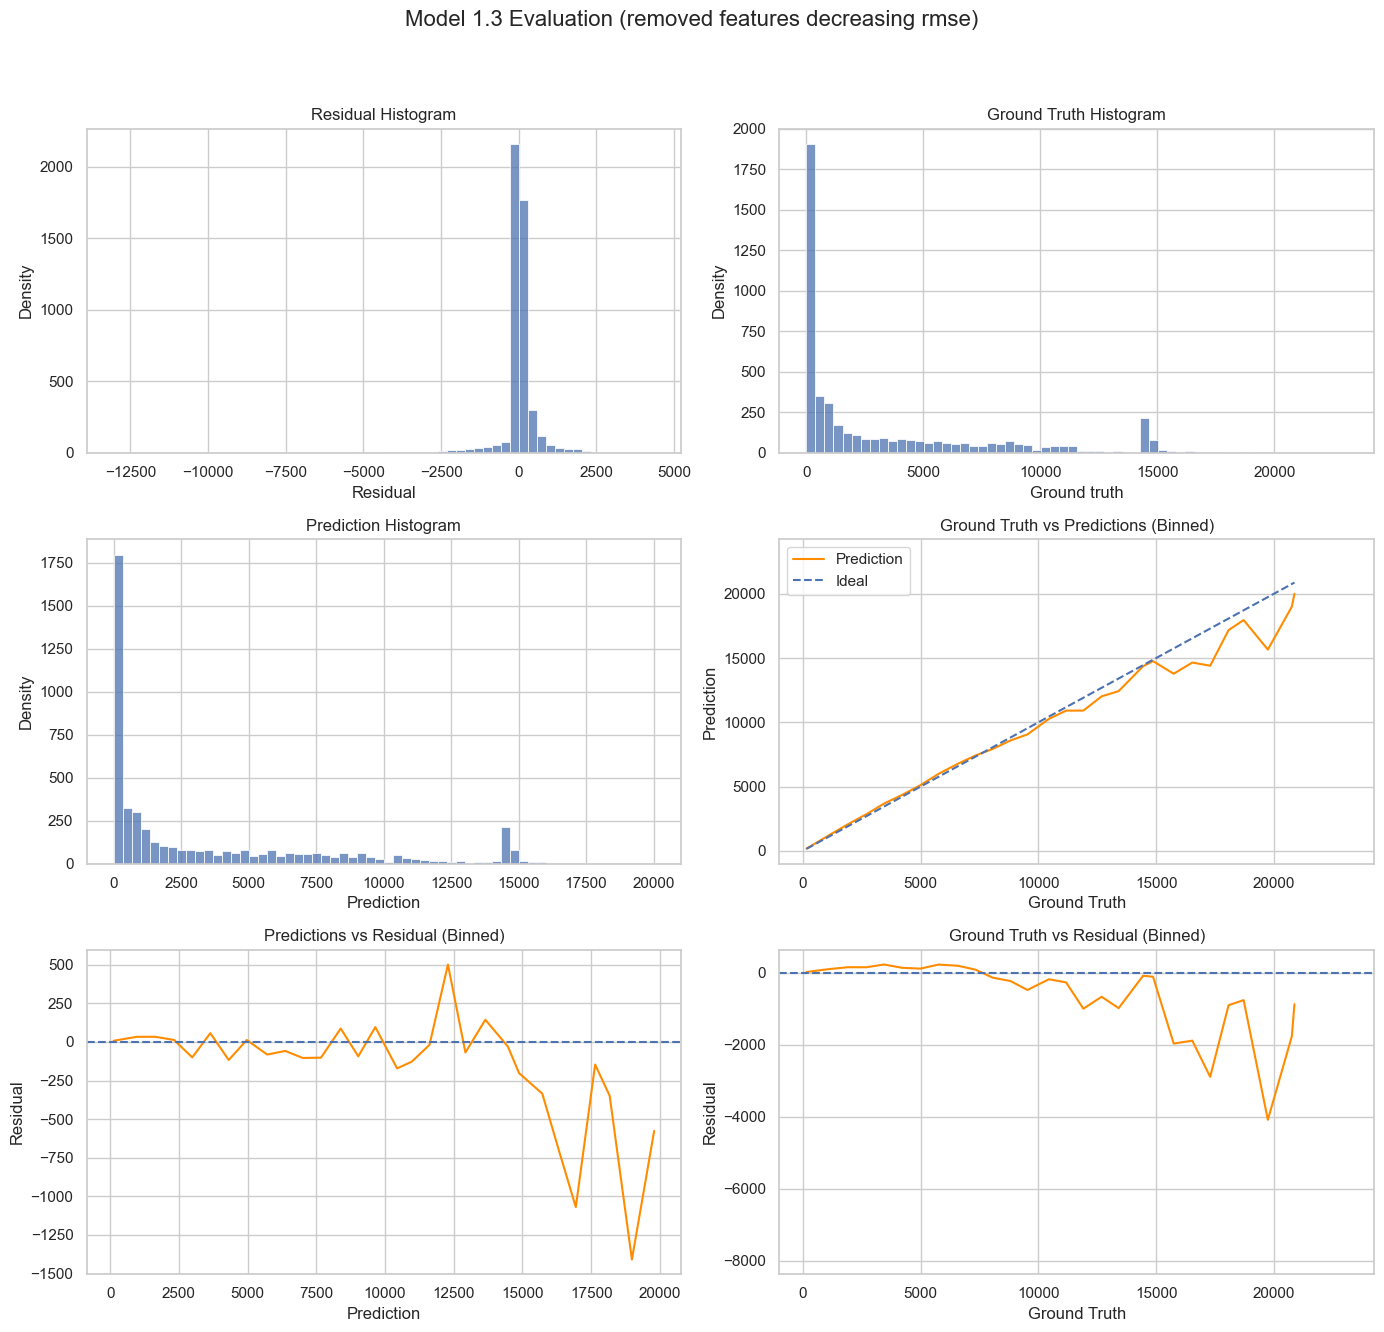

In [39]:
# evaluate modely_pred2 = model2.predict(test_df)
y_true = test_df['LIFETIME']
y_pred1_3 = model1_3.predict(test_df)
plot_model_evaluation(y_true, y_pred1_3, title="Model 1.3 Evaluation (removed features decreasing rmse)")

In [40]:
# analyze the model
analysis1_3 = model1_3.analyze(test_df)
analysis1_3

In [41]:
# save model
model1_3.save('../Models/RF1_3.ydf')

### Model 1.4 - Change label to Remaining Lifetime

In [42]:
# train model
features1_4 = ['OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH', 
             'EPOCH', 'DAYS_SINCE_LAUNCH', 'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD']
model1_4 = ydf.RandomForestLearner(task=ydf.Task.REGRESSION, features=features1_4, label='REMAINING_LIFETIME').train(train_df, verbose=2)

Train model on 19550 examples
Model trained in 0:00:39.804037


In [43]:
# describe model
description1_4 = model1_4.describe()
description1_4

In [44]:
# evaluate model
evaluation1_4 = model1_4.evaluate(test_df)
print(evaluation1_4)

RMSE: 798.34
num examples: 4888
num examples (weighted): 4888



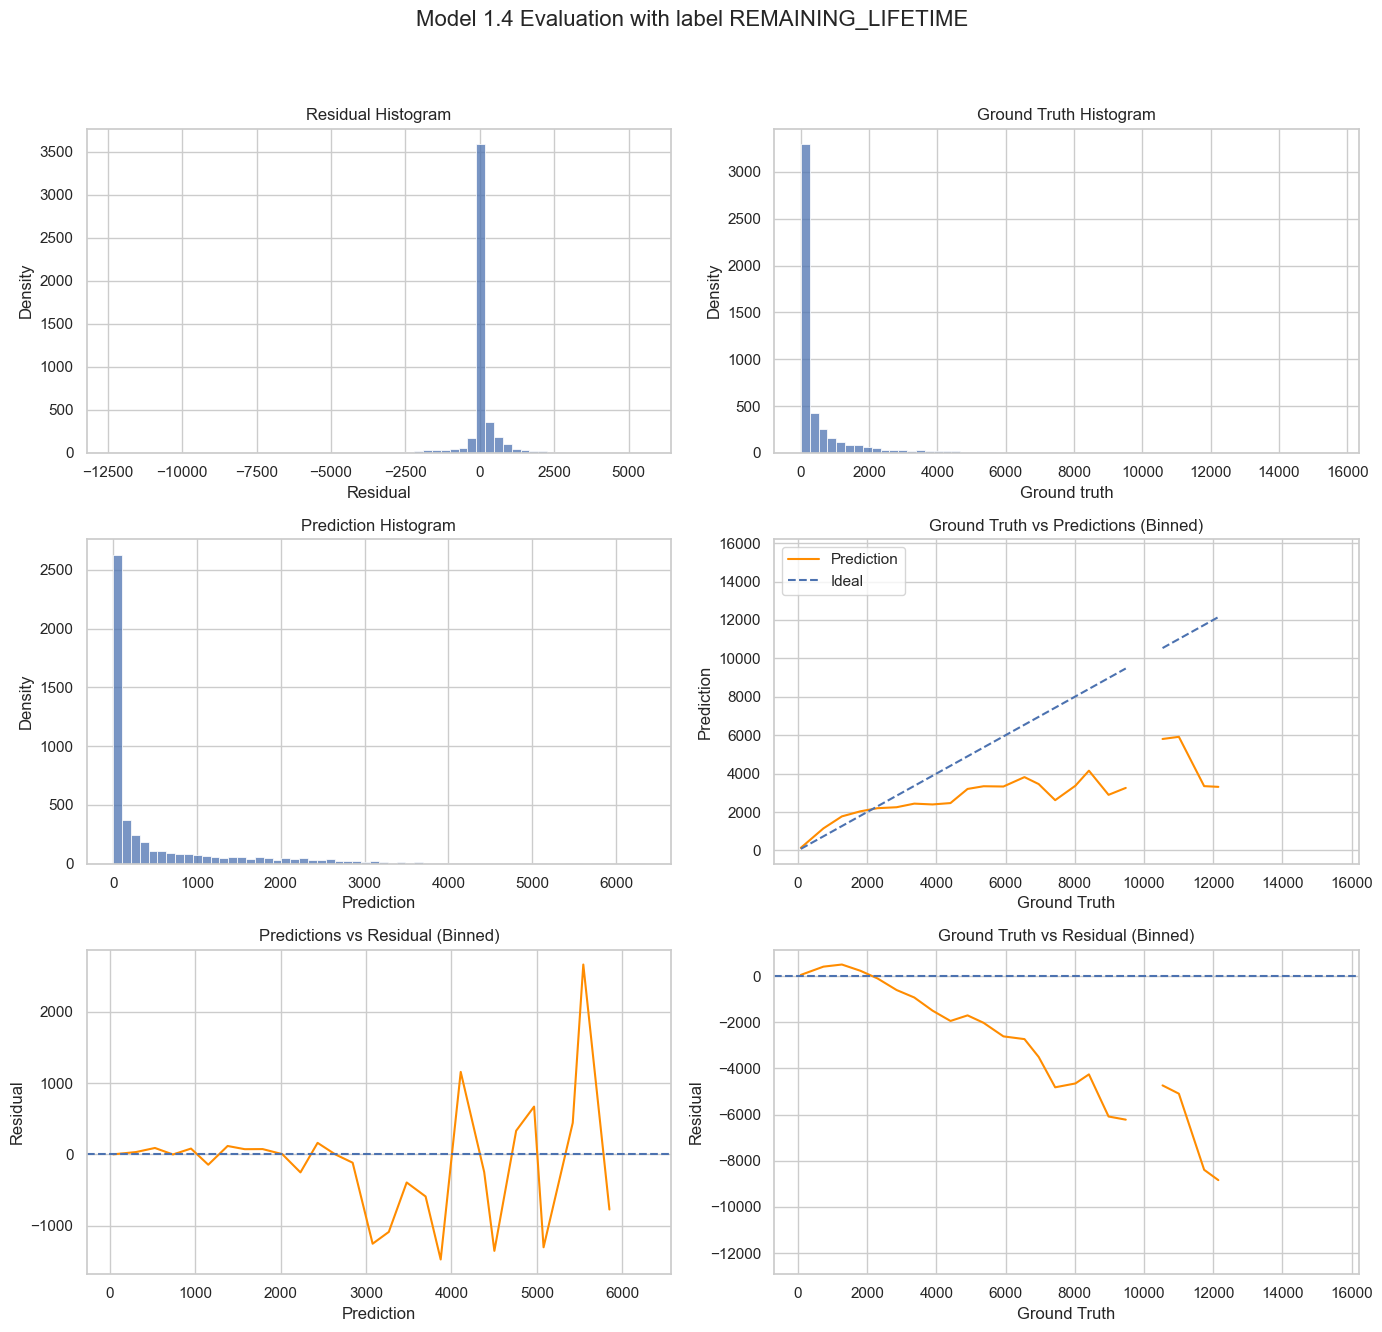

In [45]:
y_pred1_4 = model1_4.predict(test_df)
y_true = test_df['REMAINING_LIFETIME']
plot_model_evaluation(y_true, y_pred1_4, title="Model 1.4 Evaluation with label REMAINING_LIFETIME")

In [46]:
# analyze the model
analysis1_4 = model1_4.analyze(test_df)
analysis1_4

In [47]:
# save model
model1_4.save('../Models/RF1_4.ydf')

### Model 1.5 - Remove not needed features
Epoch & Right Ascension of Ascending Node

In [48]:
# train model
features1_5 = ['OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH', 
             'DAYS_SINCE_LAUNCH', 'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD']
model1_5 = ydf.RandomForestLearner(task=ydf.Task.REGRESSION, features=features1_5, label='REMAINING_LIFETIME').train(train_df, verbose=2)

Train model on 19550 examples
Model trained in 0:00:22.897104


In [49]:
# describe model
description1_5 = model1_5.describe()
description1_5

In [50]:
# evaluate model
evaluation1_5 = model1_5.evaluate(test_df)
print(evaluation1_5)

RMSE: 799.221
num examples: 4888
num examples (weighted): 4888



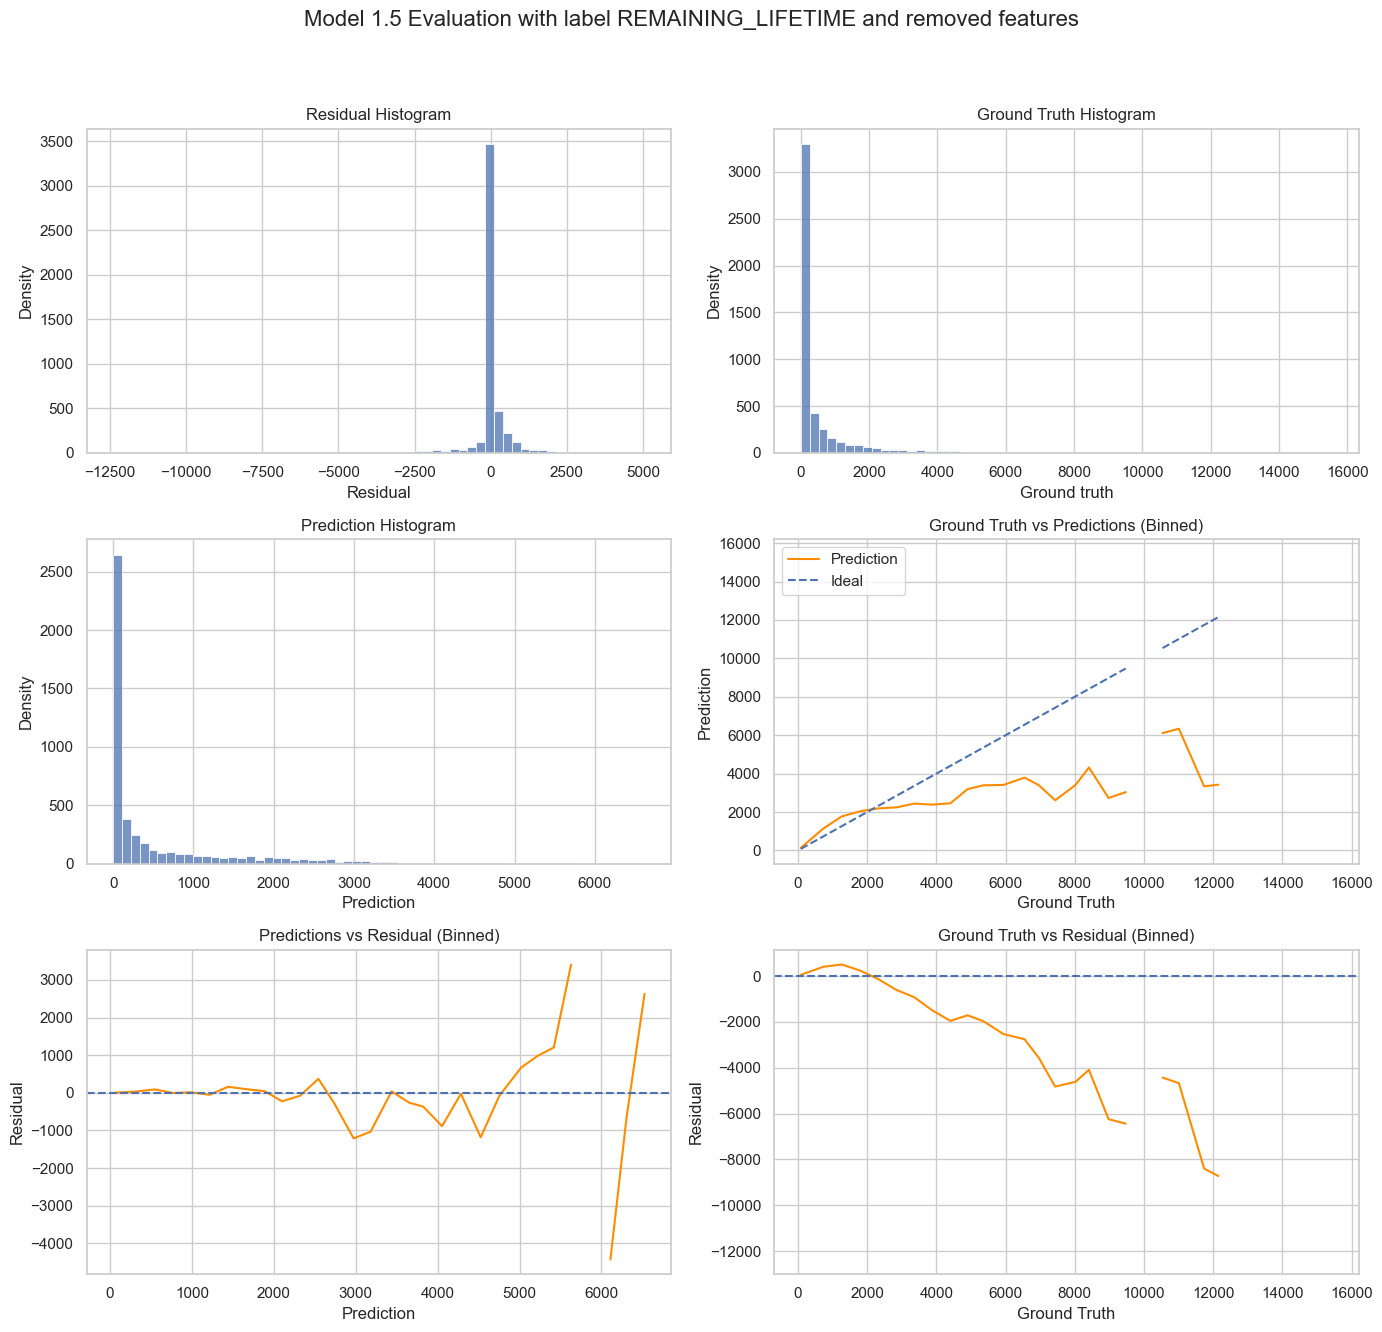

In [51]:
# plot model evaluation
y_true = test_df['REMAINING_LIFETIME']
y_pred1_5 = model1_5.predict(test_df)
plot_model_evaluation(y_true, y_pred1_5, title="Model 1.5 Evaluation with label REMAINING_LIFETIME and removed features")

In [52]:
# analyze the model
analysis1_5 = model1_5.analyze(test_df)
analysis1_5

In [53]:
# save model
model1_5.save('../Models/RF1_5.ydf')

## 2. Data Balancing

### Model 2.1 - Sample weights
Use inverse frequency based sample weights

In [67]:
# compute inverse frequency weights of years
train_df["REMAINING_LIFETIME_YEARS"] = (train_df["REMAINING_LIFETIME"] / 365).round(0).astype(int)
year_freq = train_df["REMAINING_LIFETIME_YEARS"].value_counts()
year_freq = year_freq / len(train_df) # normalize to get frequency proportion

train_df["sample_weight"] = train_df["REMAINING_LIFETIME_YEARS"].map(lambda y: 1 / year_freq[y])
train_df["sample_weight"] = train_df["sample_weight"] / train_df["sample_weight"].mean() # scale so avg weight is 1

# drop column 
train_df.drop(columns=['REMAINING_LIFETIME_YEARS'], inplace=True)

# add a dummy sample weight to the test_df to prevent errors
test_df['sample_weight'] = 1

In [60]:
# train model
features2_1 = ['OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH', 
             'EPOCH', 'DAYS_SINCE_LAUNCH', 'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD']
model2_1 = ydf.RandomForestLearner(task=ydf.Task.REGRESSION, features=features2_1, label='REMAINING_LIFETIME', weights='sample_weight').train(train_df, verbose=2)

Train model on 19550 examples
Model trained in 0:01:04.581848


In [ ]:
# describe 
model2_1.describe()

In [64]:
# evaluate
print(model2_1.evaluate(test_df))

RMSE: 885.925
num examples: 4888
num examples (weighted): 4888



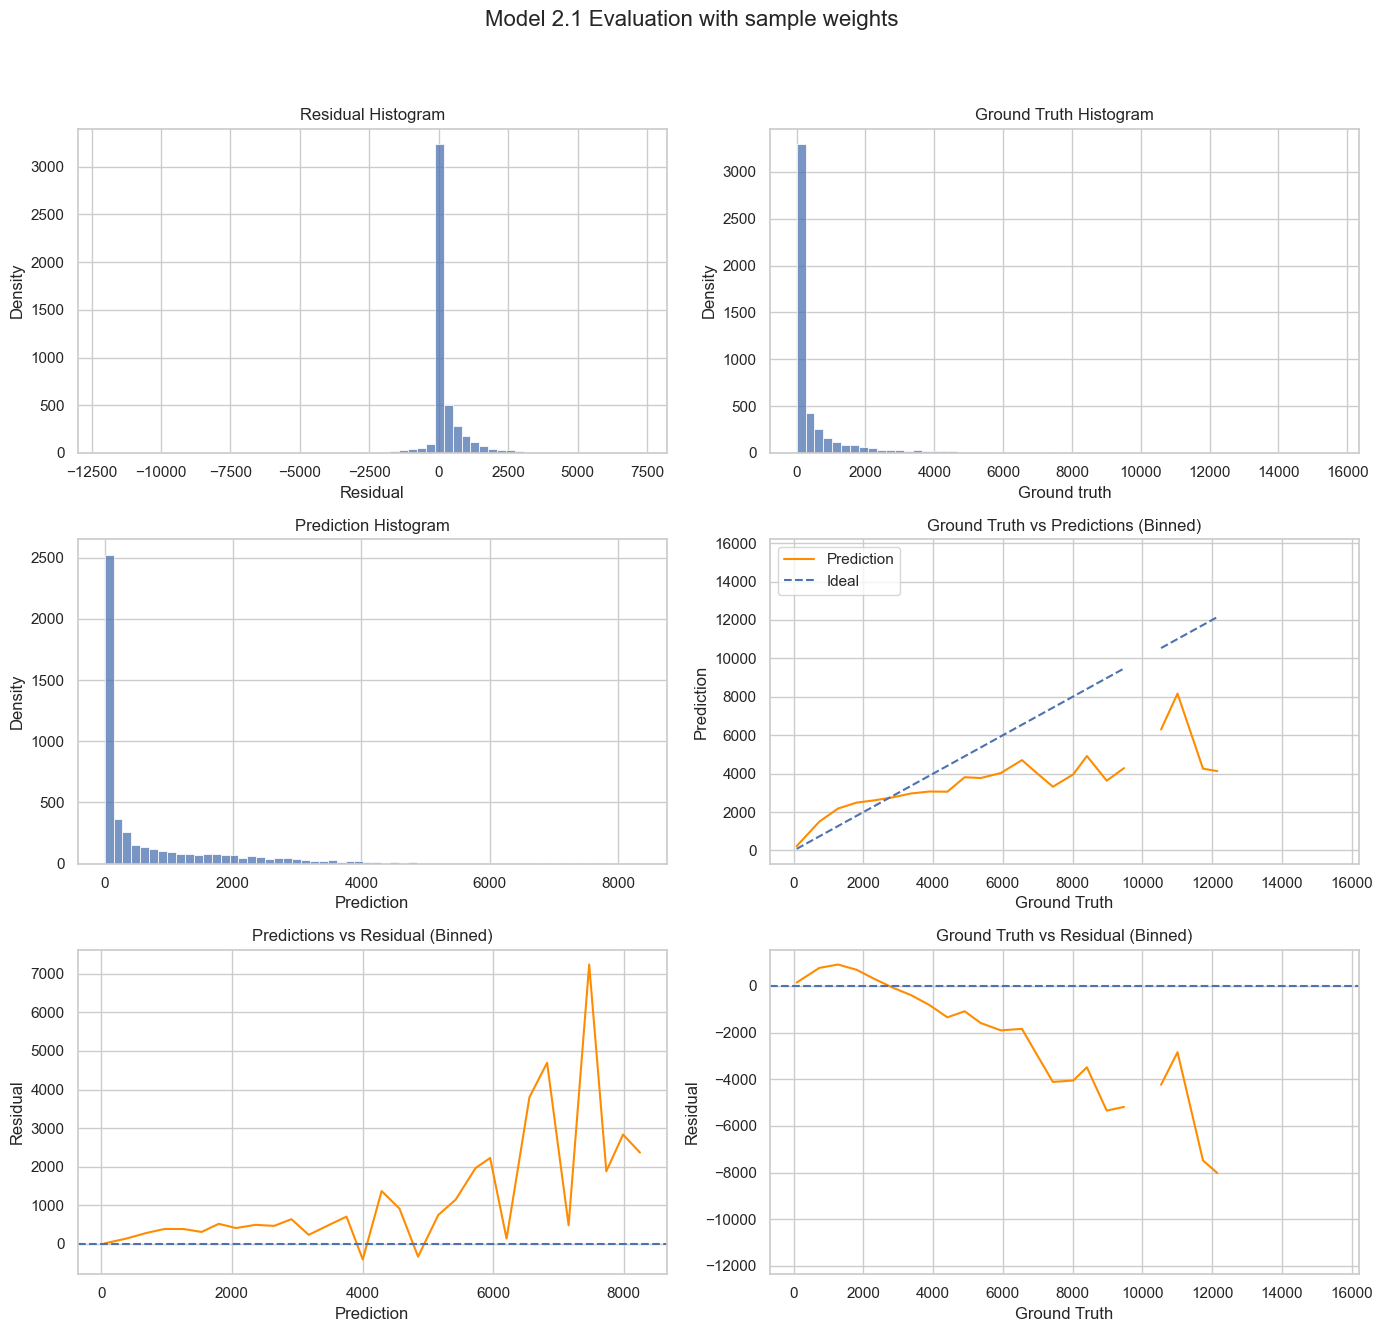

In [65]:
y_true = test_df['REMAINING_LIFETIME']
y_pred2_1 = model2_1.predict(test_df)
plot_model_evaluation(y_true, y_pred2_1, title='Model 2.1 Evaluation with sample weights')

In [68]:
# analyze
model2_1.analyze(test_df)

In [ ]:
# save model
model2_1.save('../Data/RF2_1.ydf')

### Model 2.2 - SMOTE (smogn)
Used smogn to generate synthetic samples for the minority class (longer lifetimes) and balance the dataset

In [12]:
train_smogn_df = pd.read_csv('../Data/TrainBalanced.csv')
test_smogn_df = pd.read_csv('../Data/TestBalanced.csv')

In [13]:
# train model
features2_2 = ['OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH_YEAR', 'LAUNCH_MONTH',
             'EPOCH_YEAR', 'EPOCH_MONTH', 'DAYS_SINCE_LAUNCH', 'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD']
model2_2 = ydf.RandomForestLearner(task=ydf.Task.REGRESSION, features=features2_2, label='REMAINING_LIFETIME').train(train_smogn_df, verbose=2)

Train model on 29031 examples
Model trained in 0:00:05.559733


In [14]:
# describe model
model2_2.describe()

In [15]:
# evaluate model
print(model2_2.evaluate(test_smogn_df))

RMSE: 1189.19
num examples: 7258
num examples (weighted): 7258



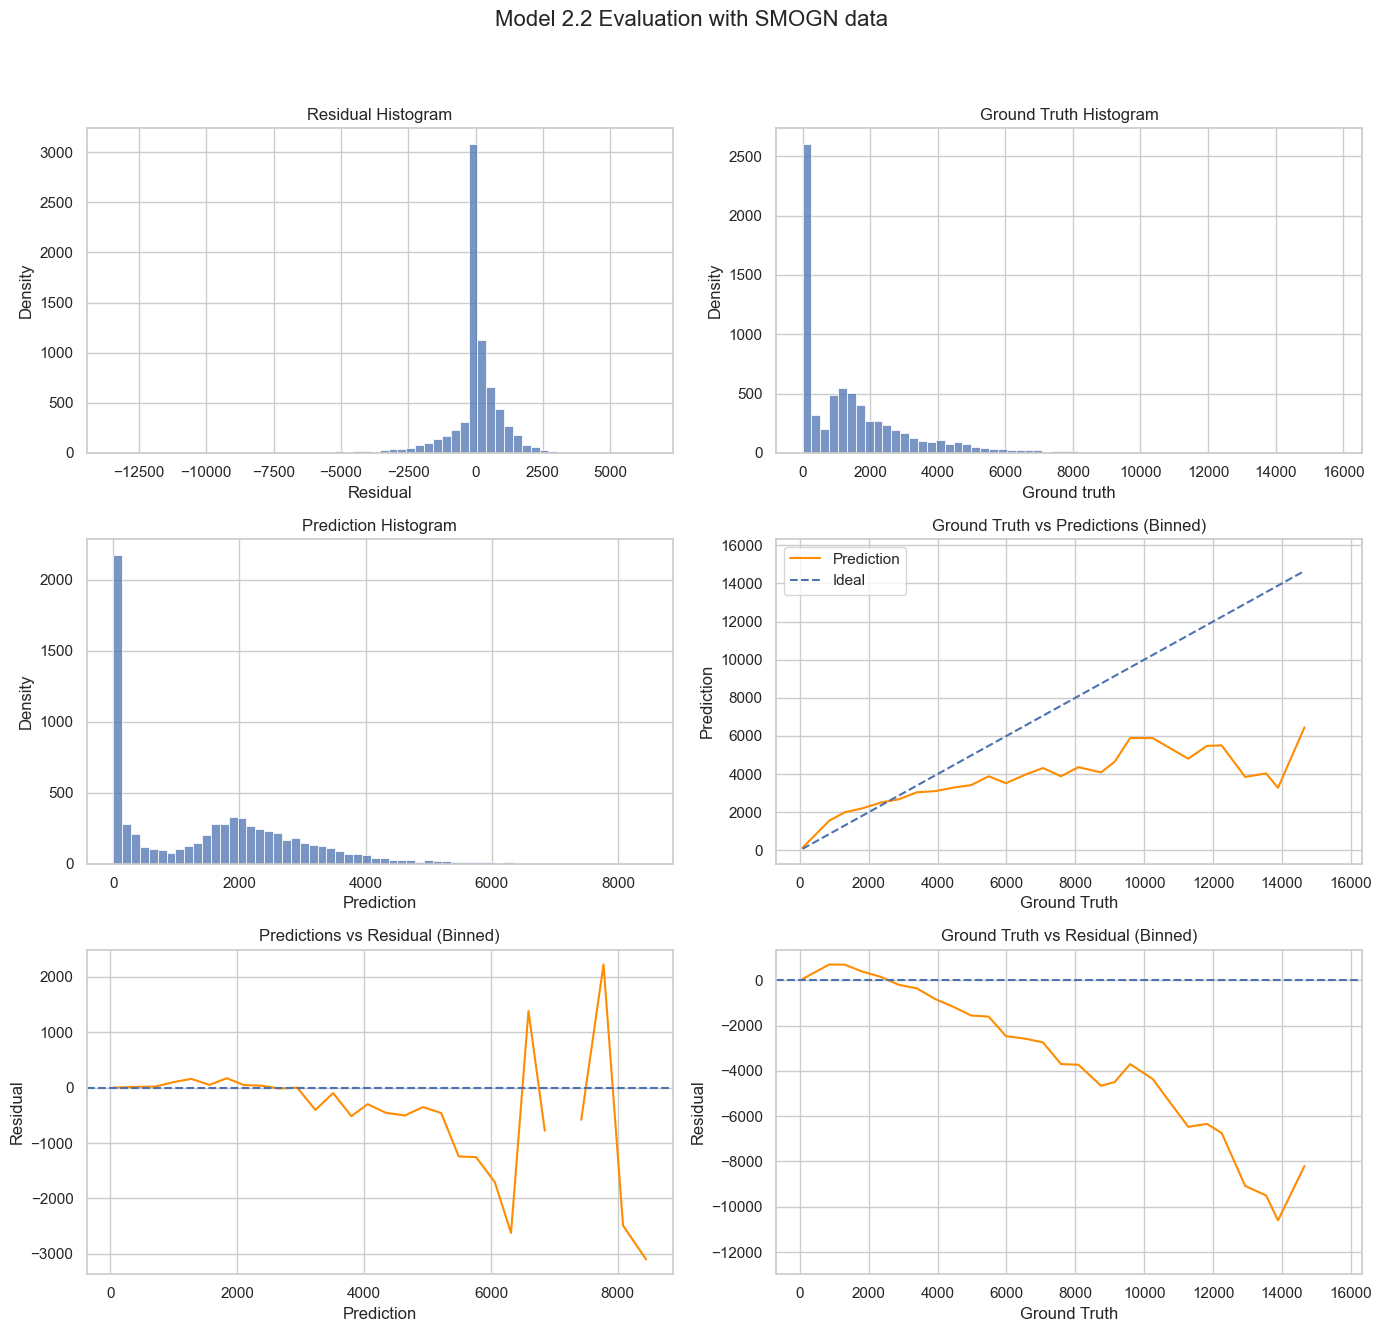

In [16]:
# plot model evaluation
y_true = test_smogn_df['REMAINING_LIFETIME']
y_pred2_2 = model2_2.predict(test_smogn_df)
plot_model_evaluation(y_true, y_pred2_2, title='Model 2.2 Evaluation with SMOGN data')

In [17]:
# analyze model
model2_2.analyze(test_smogn_df)

In [18]:
# save model
model2_2.save('../Data/RF2_2.ydf')